In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image

from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout,
    GlobalAveragePooling2D
)

from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical

from sklearn.model_selection import train_test_split

In [4]:
dataset_path = "caltech-101/101_ObjectCategories"

categories = [
    'airplanes',
    'anchor',
    'ant',
    'barrel',
    'bass'
]

num_classes = len(categories)

print("Dataset Path:", dataset_path)
print("Categories:", categories)

Dataset Path: caltech-101/101_ObjectCategories
Categories: ['airplanes', 'anchor', 'ant', 'barrel', 'bass']


In [5]:
for category in categories:

    folder = os.path.join(dataset_path, category)

    if not os.path.exists(folder):
        print("Folder not found:", folder)
    else:
        images = [
            f for f in os.listdir(folder)
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ]

        print(category, ":", len(images), "images")

airplanes : 800 images
anchor : 42 images
ant : 42 images
barrel : 47 images
bass : 54 images


In [6]:
image_paths = []
labels = []

for label, category in enumerate(categories):

    folder = os.path.join(dataset_path, category)

    for file in os.listdir(folder):

        if file.lower().endswith(('.jpg', '.jpeg', '.png')):

            image_path = os.path.join(folder, file)

            image_paths.append(image_path)
            labels.append(label)

image_paths = np.array(image_paths)
labels = np.array(labels)

print("Total Images:", len(image_paths))
print("Total Labels:", len(labels))

Total Images: 985
Total Labels: 985


In [7]:
X_train_paths, X_test_paths, y_train, y_test = train_test_split(
    image_paths,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

X_train_paths, X_val_paths, y_train, y_val = train_test_split(
    X_train_paths,
    y_train,
    test_size=0.1,
    random_state=42,
    stratify=y_train
)

print("Training Images:", len(X_train_paths))
print("Validation Images:", len(X_val_paths))
print("Testing Images:", len(X_test_paths))

Training Images: 709
Validation Images: 79
Testing Images: 197


In [8]:
def load_and_preprocess_image(path, label):

    image = tf.io.read_file(path)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(image, (224, 224))

    image = preprocess_input(image)

    label = tf.one_hot(label, num_classes)

    return image, label

In [9]:
batch_size = 16

train_ds = tf.data.Dataset.from_tensor_slices(
    (X_train_paths, y_train)
)

train_ds = train_ds.shuffle(1000)

train_ds = train_ds.map(
    load_and_preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_ds = train_ds.batch(batch_size).prefetch(
    tf.data.AUTOTUNE
)


val_ds = tf.data.Dataset.from_tensor_slices(
    (X_val_paths, y_val)
)

val_ds = val_ds.map(
    load_and_preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.batch(batch_size).prefetch(
    tf.data.AUTOTUNE
)


test_ds = tf.data.Dataset.from_tensor_slices(
    (X_test_paths, y_test)
)

test_ds = test_ds.map(
    load_and_preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.batch(batch_size).prefetch(
    tf.data.AUTOTUNE
)

print("Dataset preprocessing completed!")

Dataset preprocessing completed!


E0000 00:00:1794746860.377532   29093 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [10]:
base_model_q22 = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model_q22.trainable = False

print("VGG16 Pretrained Model Loaded!")

VGG16 Pretrained Model Loaded!


In [11]:
input_layer = Input(shape=(224, 224, 3))

x = base_model_q22(input_layer, training=False)

x = GlobalAveragePooling2D()(x)

x = Dense(256, activation='relu')(x)

x = Dropout(0.5)(x)

output_layer = Dense(
    num_classes,
    activation='softmax'
)(x)

model_q22 = Model(input_layer, output_layer)

model_q22.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,847,301 (56.64 MB)

 Trainable params: 132,613 (518.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [12]:
model_q22.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [13]:
history_q22 = model_q22.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10


/home/najanrohit0/.local/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


45/45 ━━━━━━━━━━━━━━━━━━━━ 59s 1s/step - accuracy: 0.8660 - loss: 1.2178 - val_accuracy: 0.9620 - val_loss: 0.1408
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 61s 1s/step - accuracy: 0.9732 - loss: 0.1537 - val_accuracy: 0.9747 - val_loss: 0.0525
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 61s 1s/step - accuracy: 0.9788 - loss: 0.0918 - val_accuracy: 0.9747 - val_loss: 0.0870
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 63s 1s/step - accuracy: 0.9915 - loss: 0.0375 - val_accuracy: 0.9873 - val_loss: 0.0592
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 61s 1s/step - accuracy: 0.9887 - loss: 0.0441 - val_accuracy: 0.9747 - val_loss: 0.0601
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 62s 1s/step - accuracy: 0.9929 - loss: 0.0196 - val_accuracy: 0.9873 - val_loss: 0.0136
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 63s 1s/step - accuracy: 0.9929 - loss: 0.0262 - val_accuracy: 1.0000 - val_loss: 0.0082
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 59s 1s/step - accuracy: 0.9944 - loss: 0.0261 - val_accuracy: 1.0000 - val_loss: 4.9236e-04

In [16]:
loss_q22, accuracy_q22 = model_q22.evaluate(test_ds)

print("Q22 Test Loss:", loss_q22)

print("Q22 Testing Accuracy:", accuracy_q22 * 100, "%")

13/13 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.9949 - loss: 0.0094
Q22 Test Loss: 0.009350924752652645
Q22 Testing Accuracy: 99.49238300323486 %


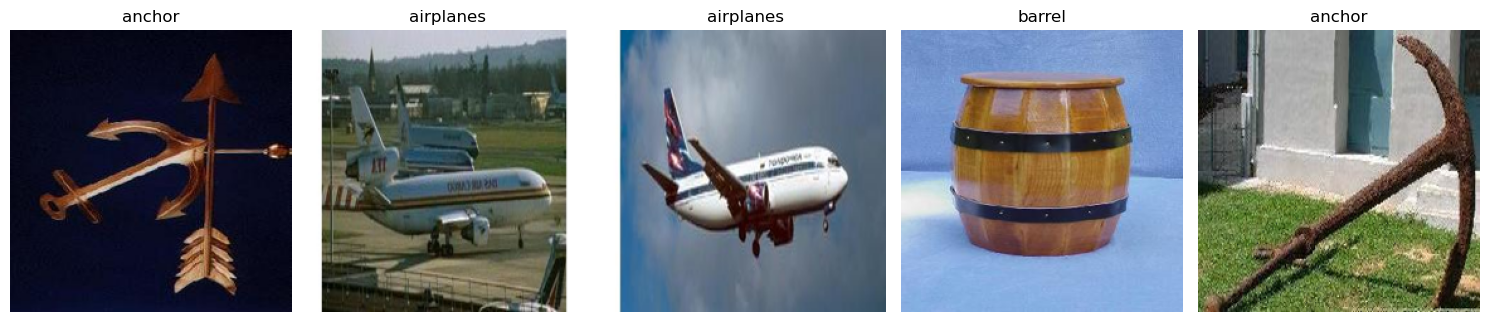

In [17]:
def predict_five_images(model, image_paths):

    plt.figure(figsize=(15, 5))

    for i in range(5):

        path = image_paths[i]

        image = Image.open(path).convert('RGB')
        image = image.resize((224, 224))

        image_array = np.array(image, dtype='float32')

        processed_image = preprocess_input(
            np.expand_dims(image_array, axis=0)
        )

        prediction = model.predict(
            processed_image,
            verbose=0
        )

        predicted_label = np.argmax(prediction[0])

        plt.subplot(1, 5, i + 1)
        plt.imshow(image)

        plt.title(categories[predicted_label])
        plt.axis('off')

    plt.tight_layout()
    plt.show()


predict_five_images(model_q22, X_test_paths)

In [18]:
# 26-VGG16 Feature Extraction

In [19]:
feature_extractor = Model(
    inputs=base_model_q22.input,
    outputs=GlobalAveragePooling2D()(
        base_model_q22.output
    )
)

print("Feature Extractor Created!")

Feature Extractor Created!


In [20]:
X_train_features = feature_extractor.predict(
    train_ds.map(lambda x, y: x),
    verbose=1
)

X_val_features = feature_extractor.predict(
    val_ds.map(lambda x, y: x),
    verbose=1
)

X_test_features = feature_extractor.predict(
    test_ds.map(lambda x, y: x),
    verbose=1
)

print("Training Features:", X_train_features.shape)
print("Validation Features:", X_val_features.shape)
print("Testing Features:", X_test_features.shape)

45/45 ━━━━━━━━━━━━━━━━━━━━ 52s 1s/step
5/5 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step
Training Features: (709, 512)
Validation Features: (79, 512)
Testing Features: (197, 512)


In [21]:
y_train_cat = to_categorical(y_train, num_classes)

y_val_cat = to_categorical(y_val, num_classes)

y_test_cat = to_categorical(y_test, num_classes)

print("Labels Converted Successfully!")

Labels Converted Successfully!


In [22]:
classifier_q26 = Sequential([
    Input(shape=(512,)),
    Dense(num_classes, activation='softmax')
])

classifier_q26.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 5)              │         2,565 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,565 (10.02 KB)

 Trainable params: 2,565 (10.02 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
classifier_q26.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [24]:
history_q26 = classifier_q26.fit(
    X_train_features,
    y_train_cat,
    validation_data=(X_val_features, y_val_cat),
    epochs=10,
    batch_size=16
)

Epoch 1/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6883 - loss: 2.1735 - val_accuracy: 0.7342 - val_loss: 2.3330
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7137 - loss: 1.5415 - val_accuracy: 0.7468 - val_loss: 2.3617
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7292 - loss: 1.2547 - val_accuracy: 0.7468 - val_loss: 2.0532
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7574 - loss: 1.0031 - val_accuracy: 0.7848 - val_loss: 2.0817
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7729 - loss: 0.8735 - val_accuracy: 0.8101 - val_loss: 1.8967
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7983 - loss: 0.7795 - val_accuracy: 0.7975 - val_loss: 1.8734
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8011 - loss: 0.7115 - val_accuracy: 0.8101 - val_loss: 2.0061
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7941 - loss: 0.6614 - val_accuracy: 0.8101 - val_loss:

In [25]:
history_q26 = classifier_q26.fit(
    X_train_features,
    y_train_cat,
    validation_data=(X_val_features, y_val_cat),
    epochs=10,
    batch_size=16
)

Epoch 1/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8434 - loss: 0.4765 - val_accuracy: 0.7975 - val_loss: 1.9802
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8420 - loss: 0.4583 - val_accuracy: 0.8228 - val_loss: 2.1472
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8575 - loss: 0.4161 - val_accuracy: 0.7975 - val_loss: 1.9644
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8632 - loss: 0.3737 - val_accuracy: 0.7722 - val_loss: 2.2618
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8702 - loss: 0.3677 - val_accuracy: 0.8101 - val_loss: 2.1178
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8829 - loss: 0.3311 - val_accuracy: 0.7722 - val_loss: 2.1219
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8999 - loss: 0.2931 - val_accuracy: 0.7089 - val_loss: 2.1639
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8984 - loss: 0.2830 - val_accuracy: 0.6709 - val_loss:

In [26]:
loss_q26, accuracy_q26 = classifier_q26.evaluate(
    X_test_features,
    y_test_cat
)

print("Q26 Test Loss:", loss_q26)

print("Q26 Testing Accuracy:", accuracy_q26 * 100, "%")

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6294 - loss: 2.7716 
Q26 Test Loss: 2.7715983390808105
Q26 Testing Accuracy: 62.944161891937256 %


In [27]:
#Q27 – VGG16 Transfer Learning with Custom Classification Head

In [28]:
base_model_q27 = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model_q27.trainable = True

for layer in base_model_q27.layers[:15]:
    layer.trainable = False

print("Lower VGG16 Layers Frozen!")

Lower VGG16 Layers Frozen!


In [29]:
input_layer = Input(shape=(224, 224, 3))

x = base_model_q27(input_layer)

x = GlobalAveragePooling2D()(x)

x = Dense(256, activation='relu')(x)

x = Dense(128, activation='relu')(x)

x = Dropout(0.5)(x)

output_layer = Dense(
    num_classes,
    activation='softmax'
)(x)

model_q27 = Model(input_layer, output_layer)

model_q27.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,879,557 (56.76 MB)

 Trainable params: 7,244,293 (27.63 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

In [30]:
model_q27.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [31]:
history_q27 = model_q27.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 68s 1s/step - accuracy: 0.7856 - loss: 0.9290 - val_accuracy: 0.9367 - val_loss: 0.1909
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 70s 2s/step - accuracy: 0.9041 - loss: 0.2405 - val_accuracy: 0.9620 - val_loss: 0.1013
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 74s 2s/step - accuracy: 0.9563 - loss: 0.1281 - val_accuracy: 0.9620 - val_loss: 0.0746
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 69s 2s/step - accuracy: 0.9704 - loss: 0.0837 - val_accuracy: 0.9494 - val_loss: 0.0722
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 71s 2s/step - accuracy: 0.9774 - loss: 0.0635 - val_accuracy: 0.9873 - val_loss: 0.0251
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 73s 2s/step - accuracy: 0.9845 - loss: 0.0454 - val_accuracy: 0.9620 - val_loss: 0.1001
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 72s 2s/step - accuracy: 0.9803 - loss: 0.0579 - val_accuracy: 1.0000 - val_loss: 0.0146
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 71s 2s/step - accuracy: 0.9929 - loss: 0.0310 - val_accuracy: 1.0000 - val_loss:

In [32]:
loss_q27, accuracy_q27 = model_q27.evaluate(test_ds)

print("Q27 Test Loss:", loss_q27)

print("Q27 Testing Accuracy:", accuracy_q27 * 100, "%")

13/13 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.9949 - loss: 0.0949
Q27 Test Loss: 0.0949280858039856
Q27 Testing Accuracy: 99.49238300323486 %


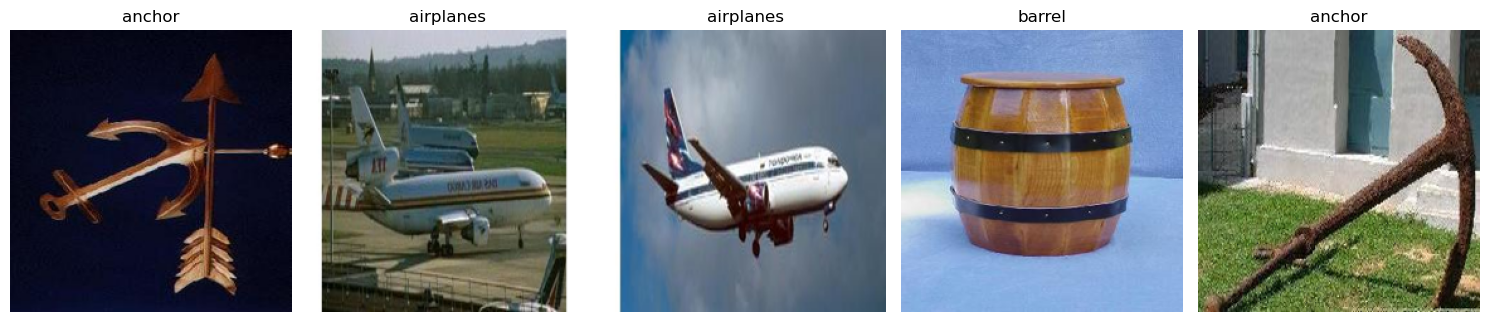

In [33]:
predict_five_images(model_q27, X_test_paths)

In [34]:
print("========== FINAL ACCURACY ==========")

print("Q22 Transfer Learning:",
      accuracy_q22 * 100, "%")

print("Q26 Feature Extraction:",
      accuracy_q26 * 100, "%")

print("Q27 Custom Classification Head:",
      accuracy_q27 * 100, "%")

========== FINAL ACCURACY ==========
Q22 Transfer Learning: 99.49238300323486 %
Q26 Feature Extraction: 62.944161891937256 %
Q27 Custom Classification Head: 99.49238300323486 %


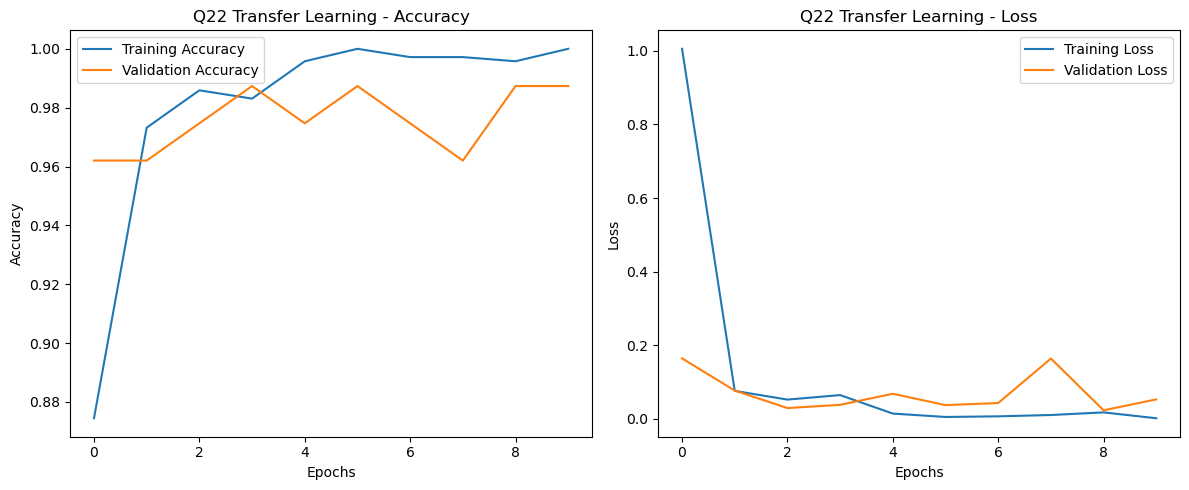

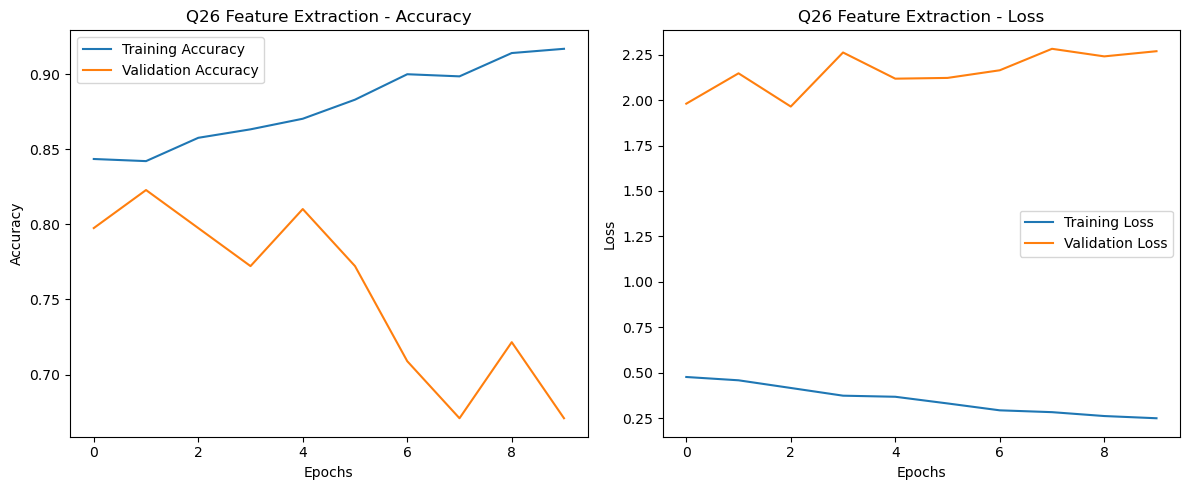

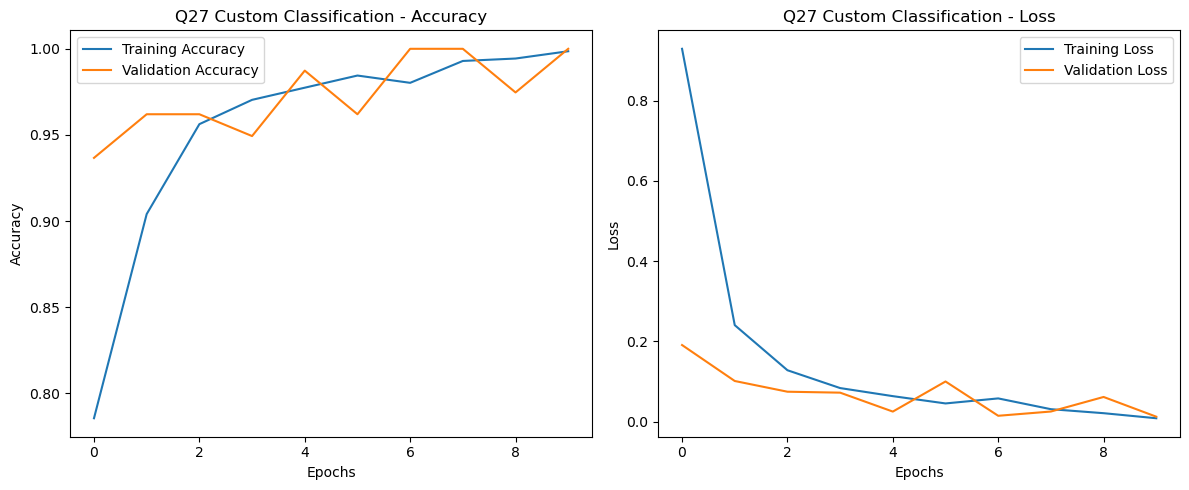

In [35]:
histories = [
    ("Q22 Transfer Learning", history_q22),
    ("Q26 Feature Extraction", history_q26),
    ("Q27 Custom Classification", history_q27)
]

for name, history in histories:

    plt.figure(figsize=(12, 5))

    # Accuracy
    plt.subplot(1, 2, 1)

    plt.plot(
        history.history['accuracy'],
        label='Training Accuracy'
    )

    plt.plot(
        history.history['val_accuracy'],
        label='Validation Accuracy'
    )

    plt.title(name + " - Accuracy")
    plt.xlabel("Epochs")
    plt.ylabel("Accuracy")
    plt.legend()

    # Loss
    plt.subplot(1, 2, 2)

    plt.plot(
        history.history['loss'],
        label='Training Loss'
    )

    plt.plot(
        history.history['val_loss'],
        label='Validation Loss'
    )

    plt.title(name + " - Loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()
    plt.show()